In [2]:
import pandas as pd
import numpy as np
from pathlib import Path

from rdkit import Chem
from rdkit.Chem import Descriptors, rdMolDescriptors
from rdkit.Chem import rdFingerprintGenerator
from rdkit import DataStructs

from sklearn.model_selection import train_test_split, GroupKFold
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from scipy.stats import spearmanr
import matplotlib.pyplot as plt

DATA_PATH = Path("../data/raw/oedb_electrolytes_v2026_05_11.csv")

df = pd.read_csv(DATA_PATH)

print("Raw dataset shape:", df.shape)
display(df.head())

Raw dataset shape: (5616, 20)


,ID,exp-ID,Cation,Anion,Solvent,Concentration (mol/kg),Ionic Conductivity (mS/cm),Viscosity (mPa·s),Cation's Diffusivity (m²/s),Anion's Diffusivity (m²/s),Solvent's Diffusivity (m²/s),Coordination (Cation←Anion),Coordination (Cation ← Solvent),Density (g/cm³),Anion SMILES,Solvent SMILES,Anion PubChem CID,Solvent PubChem CID,x,y
0,1,NaN,K,BETI,AN,0.5,18.348073,0.320151,1.280000e-09,1.090000e-09,2.510000e-09,0.177195,6.482342,0.850743,C(C(F)(F)S(=O)(=O)[N-]S(=O)(=O)C(C(F)(F)F)(F)F...,CC#N,4067273,6342,-60.781920,-21.211819
1,2,NaN,K,BETI,AN,1.0,40.029239,0.778737,1.230000e-09,7.410000e-10,2.110000e-09,0.332376,6.218885,0.933113,C(C(F)(F)S(=O)(=O)[N-]S(=O)(=O)C(C(F)(F)F)(F)F...,CC#N,4067273,6342,-60.421020,-20.695742
2,3,NaN,K,BETI,AN,1.5,28.589258,0.834437,1.090000e-09,6.840000e-10,1.830000e-09,0.473627,6.034723,1.000746,C(C(F)(F)S(=O)(=O)[N-]S(=O)(=O)C(C(F)(F)F)(F)F...,CC#N,4067273,6342,-59.876976,-19.905375
3,4,NaN,K,BETI,AN,2.0,28.614872,1.298528,7.870000e-10,5.880000e-10,1.470000e-09,0.590422,5.873371,1.066779,C(C(F)(F)S(=O)(=O)[N-]S(=O)(=O)C(C(F)(F)F)(F)F...,CC#N,4067273,6342,-59.369880,-19.195618
4,5,NaN,K,BETI,AN,2.5,37.791487,1.086047,6.760000e-10,4.690000e-10,1.200000e-09,0.741233,5.662183,1.120867,C(C(F)(F)S(=O)(=O)[N-]S(=O)(=O)C(C(F)(F)F)(F)F...,CC#N,4067273,6342,-58.683660,-18.369247


In [4]:
used_features = [
    "cation",
    "anion_smiles",
    "solvent_smiles",
    "concentration_mol_kg"
]

excluded_possible_leakage = [
    "viscosity_mpa_s",
    "cation_diffusivity_m2_s",
    "anion_diffusivity_m2_s",
    "solvent_diffusivity_m2_s",
    "coordination_cation_anion",
    "coordination_cation_solvent",
    "density_g_cm3",
    "tsne_x",
    "tsne_y"
]

leakage_audit = pd.DataFrame({
    "Column/Feature group": used_features + excluded_possible_leakage,
    "Status": ["Used as input"] * len(used_features) + ["Excluded from input"] * len(excluded_possible_leakage),
    "Reason": [
        "Composition identity",
        "Anion molecular structure",
        "Solvent molecular structure",
        "Known formulation variable",
        "Property-like output",
        "Property-like output",
        "Property-like output",
        "Property-like output",
        "Structural/property-like output",
        "Structural/property-like output",
        "Property-like output",
        "Derived visualization coordinate",
        "Derived visualization coordinate"
    ]
})

display(leakage_audit)

leakage_audit.to_csv("../outputs/metrics/leakage_audit.csv", index=False)

,Column/Feature group,Status,Reason
0,cation,Used as input,Composition identity
1,anion_smiles,Used as input,Anion molecular structure
2,solvent_smiles,Used as input,Solvent molecular structure
3,concentration_mol_kg,Used as input,Known formulation variable
4,viscosity_mpa_s,Excluded from input,Property-like output
5,cation_diffusivity_m2_s,Excluded from input,Property-like output
6,anion_diffusivity_m2_s,Excluded from input,Property-like output
7,solvent_diffusivity_m2_s,Excluded from input,Property-like output
8,coordination_cation_anion,Excluded from input,Structural/property-like output
9,coordination_cation_solvent,Excluded from input,Structural/property-like output


In [5]:
morgan_generator = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=1024)

def smiles_to_morgan_array(smiles):
    mol = Chem.MolFromSmiles(str(smiles))
    if mol is None:
        raise ValueError(f"Invalid SMILES: {smiles}")
    
    fp = morgan_generator.GetFingerprint(mol)
    arr = np.zeros((1024,), dtype=np.int8)
    DataStructs.ConvertToNumpyArray(fp, arr)
    return arr


def count_atom(mol, symbol):
    return sum(1 for atom in mol.GetAtoms() if atom.GetSymbol() == symbol)


def smiles_to_descriptors(smiles):
    mol = Chem.MolFromSmiles(str(smiles))
    if mol is None:
        raise ValueError(f"Invalid SMILES: {smiles}")

    return {
        "mol_wt": Descriptors.MolWt(mol),
        "exact_mol_wt": Descriptors.ExactMolWt(mol),
        "tpsa": Descriptors.TPSA(mol),
        "num_h_acceptors": Descriptors.NumHAcceptors(mol),
        "num_h_donors": Descriptors.NumHDonors(mol),
        "num_rotatable_bonds": Descriptors.NumRotatableBonds(mol),
        "ring_count": rdMolDescriptors.CalcNumRings(mol),
        "heavy_atom_count": Descriptors.HeavyAtomCount(mol),
        "num_hetero_atoms": rdMolDescriptors.CalcNumHeteroatoms(mol),
        "formal_charge": Chem.GetFormalCharge(mol),
        "num_f_atoms": count_atom(mol, "F"),
        "num_o_atoms": count_atom(mol, "O"),
        "num_n_atoms": count_atom(mol, "N"),
        "num_s_atoms": count_atom(mol, "S"),
    }

In [6]:
anion_fps = np.vstack(data["anion_smiles"].apply(smiles_to_morgan_array).values)
solvent_fps = np.vstack(data["solvent_smiles"].apply(smiles_to_morgan_array).values)

anion_desc = pd.DataFrame(
    data["anion_smiles"].apply(smiles_to_descriptors).tolist()
).add_prefix("anion_")

solvent_desc = pd.DataFrame(
    data["solvent_smiles"].apply(smiles_to_descriptors).tolist()
).add_prefix("solvent_")

cation_onehot = pd.get_dummies(data["cation"], prefix="cation").astype(int)

numeric_features = pd.concat([
    data[["concentration_mol_kg"]].reset_index(drop=True),
    cation_onehot.reset_index(drop=True),
    anion_desc.reset_index(drop=True),
    solvent_desc.reset_index(drop=True)
], axis=1)

X = np.hstack([
    anion_fps,
    solvent_fps,
    numeric_features.values
])

y_raw = data["ionic_conductivity_ms_cm"].values
y_log = data["log_conductivity"].values

print("Anion fingerprint matrix:", anion_fps.shape)
print("Solvent fingerprint matrix:", solvent_fps.shape)
print("Numeric feature matrix:", numeric_features.shape)
print("Final feature matrix:", X.shape)
print("Raw target:", y_raw.shape)
print("Log target:", y_log.shape)

Anion fingerprint matrix: (5595, 1024)
Solvent fingerprint matrix: (5595, 1024)
Numeric feature matrix: (5595, 32)
Final feature matrix: (5595, 2080)
Raw target: (5595,)
Log target: (5595,)


In [7]:
def safe_spearman(y_true, y_pred):
    corr = spearmanr(y_true, y_pred).correlation
    if pd.isna(corr):
        return np.nan
    return corr


def top_k_metrics(y_true, y_pred, top_fraction=0.10):
    n = len(y_true)
    k = max(1, int(n * top_fraction))
    
    true_top_idx = set(np.argsort(y_true)[-k:])
    pred_top_idx = set(np.argsort(y_pred)[-k:])
    
    hits = len(true_top_idx.intersection(pred_top_idx))
    
    precision_at_k = hits / k
    recall_at_k = hits / k
    
    return precision_at_k, recall_at_k


def compute_metrics(y_true_raw, y_pred_raw):
    mae = mean_absolute_error(y_true_raw, y_pred_raw)
    rmse = np.sqrt(mean_squared_error(y_true_raw, y_pred_raw))
    r2 = r2_score(y_true_raw, y_pred_raw)
    spearman = safe_spearman(y_true_raw, y_pred_raw)
    precision_top10, recall_top10 = top_k_metrics(y_true_raw, y_pred_raw, top_fraction=0.10)
    
    return {
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "Spearman": spearman,
        "Precision@Top10%": precision_top10,
        "Recall@Top10%": recall_top10
    }

In [8]:
def evaluate_single_split(model, X_train, X_test, y_train_log, y_test_raw):
    model.fit(X_train, y_train_log)
    
    pred_log = model.predict(X_test)
    pred_raw = (10 ** pred_log) - epsilon
    
    return compute_metrics(y_test_raw, pred_raw)

In [9]:
indices = np.arange(len(data))

train_idx, test_idx = train_test_split(
    indices,
    test_size=0.2,
    random_state=42
)

X_train, X_test = X[train_idx], X[test_idx]
y_train_log = y_log[train_idx]
y_test_raw = y_raw[test_idx]

models = {
    "Dummy Mean": DummyRegressor(strategy="mean"),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1),
    "Extra Trees": ExtraTreesRegressor(n_estimators=300, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42)
}

random_split_results = []

for model_name, model in models.items():
    metrics = evaluate_single_split(
        model,
        X_train,
        X_test,
        y_train_log,
        y_test_raw
    )
    metrics["Validation"] = "Random split"
    metrics["Model"] = model_name
    random_split_results.append(metrics)

random_split_results_df = pd.DataFrame(random_split_results)
random_split_results_df = random_split_results_df[
    ["Validation", "Model", "MAE", "RMSE", "R2", "Spearman", "Precision@Top10%", "Recall@Top10%"]
]

display(random_split_results_df)

C:\Users\avail\AppData\Local\Temp\ipykernel_55464\2014417984.py:2: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  corr = spearmanr(y_true, y_pred).correlation


,Validation,Model,MAE,RMSE,R2,Spearman,Precision@Top10%,Recall@Top10%
0,Random split,Dummy Mean,5.517865,13.028978,-0.150007,NaN,0.081081,0.081081
1,Random split,Random Forest,2.001895,5.576282,0.789346,0.962890,0.900901,0.900901
2,Random split,Extra Trees,2.142166,6.086243,0.749055,0.960269,0.900901,0.900901
3,Random split,Gradient Boosting,2.342154,6.015902,0.754822,0.922004,0.882883,0.882883


In [10]:
def evaluate_group_kfold(model, X, y_log, y_raw, groups, validation_name, n_splits=5):
    gkf = GroupKFold(n_splits=n_splits)
    
    fold_results = []
    
    for fold, (train_idx, test_idx) in enumerate(gkf.split(X, y_raw, groups=groups), start=1):
        X_train, X_test = X[train_idx], X[test_idx]
        y_train_log = y_log[train_idx]
        y_test_raw = y_raw[test_idx]
        
        model.fit(X_train, y_train_log)
        
        pred_log = model.predict(X_test)
        pred_raw = (10 ** pred_log) - epsilon
        
        metrics = compute_metrics(y_test_raw, pred_raw)
        metrics["Validation"] = validation_name
        metrics["Fold"] = fold
        metrics["Model"] = model.__class__.__name__
        metrics["Test groups"] = ", ".join(map(str, sorted(pd.Series(groups[test_idx]).unique())))
        
        fold_results.append(metrics)
    
    return pd.DataFrame(fold_results)

In [11]:
solvent_groups = data["solvent"].values

solvent_cv_results = []

for model_name, model in models.items():
    if model_name == "Dummy Mean":
        continue
    
    result = evaluate_group_kfold(
        model=model,
        X=X,
        y_log=y_log,
        y_raw=y_raw,
        groups=solvent_groups,
        validation_name="Solvent GroupKFold",
        n_splits=5
    )
    result["Model"] = model_name
    solvent_cv_results.append(result)

solvent_cv_results_df = pd.concat(solvent_cv_results, ignore_index=True)

display(solvent_cv_results_df)

,MAE,RMSE,R2,Spearman,Precision@Top10%,Recall@Top10%,Validation,Fold,Model,Test groups
0,6.317141,12.653897,0.377558,0.709470,0.691589,0.691589,Solvent GroupKFold,1,Random Forest,"Ac, Ac2O, EA, MA, TMP"
1,6.958300,12.924461,0.463352,0.480153,0.500000,0.500000,Solvent GroupKFold,2,Random Forest,"AN, DMC, DMSO, EMC, GN, SN"
2,5.774561,9.537353,0.359573,0.545884,0.691589,0.691589,Solvent GroupKFold,3,Random Forest,"DMI, EB, FAN, GBL, TEP"
3,1.520772,2.161801,0.447467,0.761320,0.355140,0.355140,Solvent GroupKFold,4,Random Forest,"DEC, EC, FEA, FEMC, PC"
4,1.008411,1.514680,0.535505,0.808323,0.420561,0.420561,Solvent GroupKFold,5,Random Forest,"BC, EP, FEC, MB, MP"
5,6.258295,12.612614,0.381613,0.729225,0.700935,0.700935,Solvent GroupKFold,1,Extra Trees,"Ac, Ac2O, EA, MA, TMP"
6,6.377400,12.145450,0.526095,0.476061,0.562500,0.562500,Solvent GroupKFold,2,Extra Trees,"AN, DMC, DMSO, EMC, GN, SN"
7,5.547479,10.592408,0.210044,0.589757,0.336449,0.336449,Solvent GroupKFold,3,Extra Trees,"DMI, EB, FAN, GBL, TEP"
8,1.454891,2.235963,0.408906,0.686667,0.411215,0.411215,Solvent GroupKFold,4,Extra Trees,"DEC, EC, FEA, FEMC, PC"
9,0.950735,1.492960,0.548730,0.825005,0.485981,0.485981,Solvent GroupKFold,5,Extra Trees,"BC, EP, FEC, MB, MP"


In [12]:
anion_groups = data["anion"].values

anion_cv_results = []

for model_name, model in models.items():
    if model_name == "Dummy Mean":
        continue
    
    result = evaluate_group_kfold(
        model=model,
        X=X,
        y_log=y_log,
        y_raw=y_raw,
        groups=anion_groups,
        validation_name="Anion GroupKFold",
        n_splits=5
    )
    result["Model"] = model_name
    anion_cv_results.append(result)

anion_cv_results_df = pd.concat(anion_cv_results, ignore_index=True)

display(anion_cv_results_df)

,MAE,RMSE,R2,Spearman,Precision@Top10%,Recall@Top10%,Validation,Fold,Model,Test groups
0,2.405245,6.471396,0.679814,0.903899,0.846774,0.846774,Anion GroupKFold,1,Random Forest,"OTf, TFSI"
1,3.486389,8.232709,0.609783,0.836934,0.766129,0.766129,Anion GroupKFold,2,Random Forest,"BF4, FSI"
2,2.984773,7.505792,0.145419,0.849891,0.634146,0.634146,Anion GroupKFold,3,Random Forest,"DFOB, TFA"
3,2.241159,5.662275,0.684082,0.961142,0.903226,0.903226,Anion GroupKFold,4,Random Forest,BETI
4,4.500875,11.753527,0.535123,0.867300,0.758065,0.758065,Anion GroupKFold,5,Random Forest,"ClO4, PF6"
5,2.484802,6.516749,0.675310,0.917821,0.806452,0.806452,Anion GroupKFold,1,Extra Trees,"OTf, TFSI"
6,3.518318,8.111525,0.621187,0.808976,0.774194,0.774194,Anion GroupKFold,2,Extra Trees,"BF4, FSI"
7,3.219215,8.100485,0.004636,0.838627,0.601626,0.601626,Anion GroupKFold,3,Extra Trees,"DFOB, TFA"
8,2.632194,6.964513,0.522059,0.955471,0.854839,0.854839,Anion GroupKFold,4,Extra Trees,BETI
9,4.404934,11.590005,0.547968,0.845455,0.750000,0.750000,Anion GroupKFold,5,Extra Trees,"ClO4, PF6"


In [13]:
concentration_groups = data["concentration_mol_kg"].values

concentration_cv_results = []

for model_name, model in models.items():
    if model_name == "Dummy Mean":
        continue
    
    result = evaluate_group_kfold(
        model=model,
        X=X,
        y_log=y_log,
        y_raw=y_raw,
        groups=concentration_groups,
        validation_name="Concentration GroupKFold",
        n_splits=4
    )
    result["Model"] = model_name
    concentration_cv_results.append(result)

concentration_cv_results_df = pd.concat(concentration_cv_results, ignore_index=True)

display(concentration_cv_results_df)

,MAE,RMSE,R2,Spearman,Precision@Top10%,Recall@Top10%,Validation,Fold,Model,Test groups
0,2.034483,5.035505,0.775339,0.954271,0.884892,0.884892,Concentration GroupKFold,1,Random Forest,"0.5, 4.0"
1,2.077040,5.608451,0.808314,0.955551,0.900000,0.900000,Concentration GroupKFold,2,Random Forest,"1.5, 3.5"
2,2.289518,6.233686,0.738472,0.944425,0.841727,0.841727,Concentration GroupKFold,3,Random Forest,"1.0, 3.0"
3,2.576275,7.126119,0.771924,0.945299,0.899281,0.899281,Concentration GroupKFold,4,Random Forest,"2.0, 2.5"
4,2.325614,5.822221,0.699656,0.948038,0.863309,0.863309,Concentration GroupKFold,1,Extra Trees,"0.5, 4.0"
5,2.017587,5.512562,0.814812,0.962295,0.907143,0.907143,Concentration GroupKFold,2,Extra Trees,"1.5, 3.5"
6,2.016749,5.573820,0.790910,0.964731,0.884892,0.884892,Concentration GroupKFold,3,Extra Trees,"1.0, 3.0"
7,2.510967,7.432915,0.751863,0.956495,0.899281,0.899281,Concentration GroupKFold,4,Extra Trees,"2.0, 2.5"
8,2.364094,6.181306,0.661466,0.907168,0.856115,0.856115,Concentration GroupKFold,1,Gradient Boosting,"0.5, 4.0"
9,2.410939,6.119036,0.771823,0.916371,0.864286,0.864286,Concentration GroupKFold,2,Gradient Boosting,"1.5, 3.5"


In [14]:
all_cv_results = pd.concat(
    [
        solvent_cv_results_df,
        anion_cv_results_df,
        concentration_cv_results_df
    ],
    ignore_index=True
)

summary_cv = (
    all_cv_results
    .groupby(["Validation", "Model"])
    .agg(
        MAE_mean=("MAE", "mean"),
        MAE_std=("MAE", "std"),
        RMSE_mean=("RMSE", "mean"),
        RMSE_std=("RMSE", "std"),
        R2_mean=("R2", "mean"),
        R2_std=("R2", "std"),
        Spearman_mean=("Spearman", "mean"),
        Spearman_std=("Spearman", "std"),
        PrecisionTop10_mean=("Precision@Top10%", "mean"),
        PrecisionTop10_std=("Precision@Top10%", "std")
    )
    .reset_index()
)

display(summary_cv)

all_cv_results.to_csv("../outputs/metrics/groupkfold_foldwise_results.csv", index=False)
summary_cv.to_csv("../outputs/metrics/groupkfold_summary_results.csv", index=False)

,Validation,Model,MAE_mean,MAE_std,RMSE_mean,RMSE_std,R2_mean,R2_std,Spearman_mean,Spearman_std,PrecisionTop10_mean,PrecisionTop10_std
0,Anion GroupKFold,Extra Trees,3.251893,0.770391,8.256655,1.990827,0.474232,0.269385,0.873270,0.060929,0.757422,0.095528
1,Anion GroupKFold,Gradient Boosting,3.164576,1.081519,7.712071,2.940782,0.588322,0.128014,0.861091,0.040682,0.767152,0.083299
2,Anion GroupKFold,Random Forest,3.123688,0.914127,7.925140,2.353770,0.530844,0.223873,0.883833,0.050010,0.781668,0.101951
3,Concentration GroupKFold,Extra Trees,2.217729,0.243638,6.085379,0.908280,0.764310,0.050309,0.957890,0.007421,0.888656,0.019246
4,Concentration GroupKFold,Gradient Boosting,2.576598,0.320158,6.606223,1.104733,0.723836,0.054792,0.911575,0.005050,0.847366,0.027979
5,Concentration GroupKFold,Random Forest,2.244329,0.247825,6.000940,0.895603,0.773512,0.028547,0.949886,0.005836,0.881475,0.027397
6,Solvent GroupKFold,Extra Trees,4.117760,2.685744,7.815879,5.490395,0.415078,0.135448,0.661343,0.133687,0.499416,0.140630
7,Solvent GroupKFold,Gradient Boosting,4.000637,2.552844,8.320297,5.696601,0.305323,0.172199,0.682007,0.118004,0.453943,0.218352
8,Solvent GroupKFold,Random Forest,4.315837,2.822550,7.758438,5.570564,0.436691,0.070772,0.661030,0.141488,0.531776,0.154644


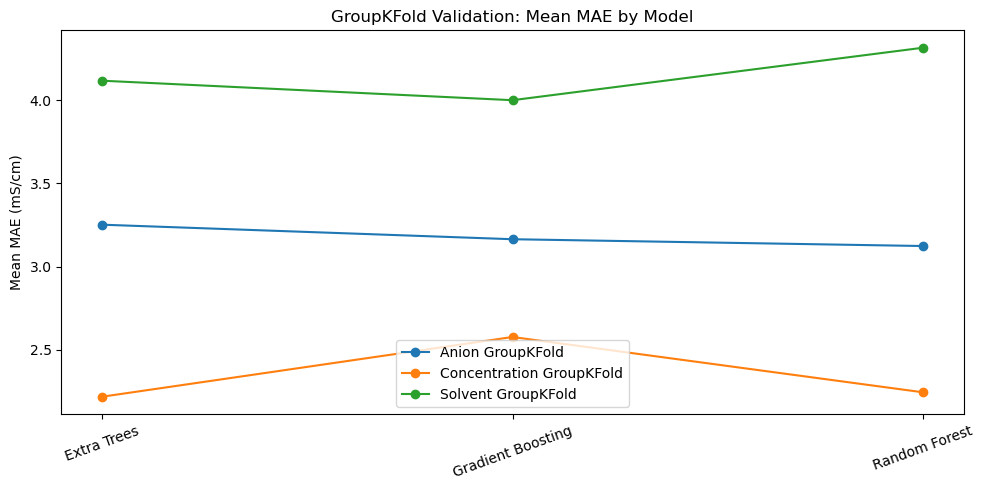

In [15]:
plt.figure(figsize=(10, 5))

for validation_name in summary_cv["Validation"].unique():
    subset = summary_cv[summary_cv["Validation"] == validation_name]
    plt.plot(
        subset["Model"],
        subset["MAE_mean"],
        marker="o",
        label=validation_name
    )

plt.ylabel("Mean MAE (mS/cm)")
plt.title("GroupKFold Validation: Mean MAE by Model")
plt.xticks(rotation=20)
plt.legend()
plt.tight_layout()

plt.savefig("../outputs/figures/groupkfold_mean_mae_comparison.png", dpi=300)
plt.show()

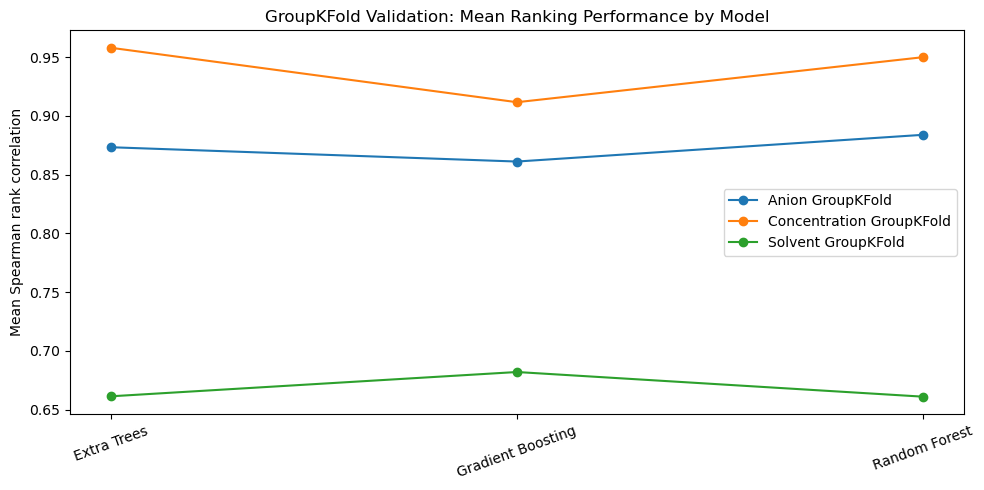

In [16]:
plt.figure(figsize=(10, 5))

for validation_name in summary_cv["Validation"].unique():
    subset = summary_cv[summary_cv["Validation"] == validation_name]
    plt.plot(
        subset["Model"],
        subset["Spearman_mean"],
        marker="o",
        label=validation_name
    )

plt.ylabel("Mean Spearman rank correlation")
plt.title("GroupKFold Validation: Mean Ranking Performance by Model")
plt.xticks(rotation=20)
plt.legend()
plt.tight_layout()

plt.savefig("../outputs/figures/groupkfold_mean_spearman_comparison.png", dpi=300)
plt.show()

In [17]:
best_by_mae = (
    summary_cv
    .sort_values(["Validation", "MAE_mean"])
    .groupby("Validation")
    .head(1)
    .reset_index(drop=True)
)

display(best_by_mae)

best_by_mae.to_csv("../outputs/metrics/best_model_by_validation_mae.csv", index=False)

,Validation,Model,MAE_mean,MAE_std,RMSE_mean,RMSE_std,R2_mean,R2_std,Spearman_mean,Spearman_std,PrecisionTop10_mean,PrecisionTop10_std
0,Anion GroupKFold,Random Forest,3.123688,0.914127,7.925140,2.353770,0.530844,0.223873,0.883833,0.050010,0.781668,0.101951
1,Concentration GroupKFold,Extra Trees,2.217729,0.243638,6.085379,0.908280,0.764310,0.050309,0.957890,0.007421,0.888656,0.019246
2,Solvent GroupKFold,Gradient Boosting,4.000637,2.552844,8.320297,5.696601,0.305323,0.172199,0.682007,0.118004,0.453943,0.218352


In [18]:
hardest_folds = (
    all_cv_results
    .sort_values("MAE", ascending=False)
    [[
        "Validation",
        "Fold",
        "Model",
        "Test groups",
        "MAE",
        "RMSE",
        "R2",
        "Spearman",
        "Precision@Top10%"
    ]]
    .head(15)
)

display(hardest_folds)

hardest_folds.to_csv("../outputs/metrics/hardest_groupkfold_folds.csv", index=False)

,Validation,Fold,Model,Test groups,MAE,RMSE,R2,Spearman,Precision@Top10%
1,Solvent GroupKFold,2,Random Forest,"AN, DMC, DMSO, EMC, GN, SN",6.958300,12.924461,0.463352,0.480153,0.500000
11,Solvent GroupKFold,2,Gradient Boosting,"AN, DMC, DMSO, EMC, GN, SN",6.456200,13.099815,0.448691,0.483581,0.578125
6,Solvent GroupKFold,2,Extra Trees,"AN, DMC, DMSO, EMC, GN, SN",6.377400,12.145450,0.526095,0.476061,0.562500
0,Solvent GroupKFold,1,Random Forest,"Ac, Ac2O, EA, MA, TMP",6.317141,12.653897,0.377558,0.709470,0.691589
5,Solvent GroupKFold,1,Extra Trees,"Ac, Ac2O, EA, MA, TMP",6.258295,12.612614,0.381613,0.729225,0.700935
10,Solvent GroupKFold,1,Gradient Boosting,"Ac, Ac2O, EA, MA, TMP",6.233513,12.491060,0.393475,0.758773,0.710280
2,Solvent GroupKFold,3,Random Forest,"DMI, EB, FAN, GBL, TEP",5.774561,9.537353,0.359573,0.545884,0.691589
7,Solvent GroupKFold,3,Extra Trees,"DMI, EB, FAN, GBL, TEP",5.547479,10.592408,0.210044,0.589757,0.336449
12,Solvent GroupKFold,3,Gradient Boosting,"DMI, EB, FAN, GBL, TEP",4.688175,11.795930,0.020334,0.744586,0.186916
29,Anion GroupKFold,5,Gradient Boosting,"ClO4, PF6",4.636574,11.937345,0.520468,0.858767,0.790323


In [19]:
validation_difficulty = (
    summary_cv
    .groupby("Validation")
    .agg(
        avg_MAE=("MAE_mean", "mean"),
        avg_RMSE=("RMSE_mean", "mean"),
        avg_R2=("R2_mean", "mean"),
        avg_Spearman=("Spearman_mean", "mean"),
        avg_PrecisionTop10=("PrecisionTop10_mean", "mean")
    )
    .sort_values("avg_MAE", ascending=False)
    .reset_index()
)

display(validation_difficulty)

validation_difficulty.to_csv("../outputs/metrics/validation_difficulty_ranking.csv", index=False)

,Validation,avg_MAE,avg_RMSE,avg_R2,avg_Spearman,avg_PrecisionTop10
0,Solvent GroupKFold,4.144745,7.964872,0.385697,0.668127,0.495045
1,Anion GroupKFold,3.180052,7.964622,0.531133,0.872731,0.768747
2,Concentration GroupKFold,2.346219,6.230847,0.753886,0.939784,0.872499


In [20]:
notebook3_conclusion = pd.DataFrame([
    {
        "Finding": "Concentration generalization is strongest",
        "Evidence": "Lowest MAE and highest Spearman under Concentration GroupKFold",
        "Implication": "Model learns concentration-dependent trends reasonably well"
    },
    {
        "Finding": "Anion generalization is moderate to strong",
        "Evidence": "Anion GroupKFold gives moderate MAE and high Spearman",
        "Implication": "Molecular fingerprints and descriptors transfer reasonably across anions"
    },
    {
        "Finding": "Solvent generalization is the main bottleneck",
        "Evidence": "Solvent GroupKFold gives highest MAE and lowest Top10 precision",
        "Implication": "Next model improvements should focus on solvent representation and uncertainty"
    },
    {
        "Finding": "Random split alone is insufficient",
        "Evidence": "Grouped validations reveal different levels of difficulty",
        "Implication": "Future model selection should use GroupKFold, not only train_test_split"
    }
])

display(notebook3_conclusion)

notebook3_conclusion.to_csv("../outputs/metrics/notebook3_conclusion.csv", index=False)

,Finding,Evidence,Implication
0,Concentration generalization is strongest,Lowest MAE and highest Spearman under Concentr...,Model learns concentration-dependent trends re...
1,Anion generalization is moderate to strong,Anion GroupKFold gives moderate MAE and high S...,Molecular fingerprints and descriptors transfe...
2,Solvent generalization is the main bottleneck,Solvent GroupKFold gives highest MAE and lowes...,Next model improvements should focus on solven...
3,Random split alone is insufficient,Grouped validations reveal different levels of...,"Future model selection should use GroupKFold, ..."
